# 10. Final evaluation on the held-out test split

Everything evaluated here was **fixed before this notebook was run**: the representation,
hyperparameters and class weighting of each model family are read from
`results/selection.json`, written by notebooks 04–05 (validation split) and confirmed or
changed by 5-fold cross-validation on train in notebook 09. The per-label thresholds come
from notebook 07 (validation only). Nothing is tuned on `test`.

**Disclosure.** An earlier version of this notebook (then numbered 08) was executed on
14 Nov 2026, before the proposal items of notebook 09 existed. This run adds two things
chosen without looking at test: the TF-IDF + structural-features SVM, and the three binary
focus-fallacy detectors. CV in notebook 09 left every earlier choice unchanged, so the rows
shared with the earlier run are identical.

Models are refitted on `train` only (not train+val) so that the validation-tuned thresholds
remain valid for the same model.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import multilabel_confusion_matrix
from src.config import RESULTS, FIGURES, NEAR_DUP_HIGH, NEAR_DUP_LOW
from src.data import load_dataset, get_splits
from src.features import word_tfidf, word_bow
from src.models import (logreg, linear_svm, pca_logreg, svd_rbf_svm, PriorBaseline,
                        StratifiedRandomBaseline, scores_of)
from src.structural import TfidfPlusStructural
from src.evaluate import scores, per_class_f1, bootstrap_ci
from src.neardup import max_sim_to_train, bucket
from src import shortcuts as sc

df, LABELS = load_dataset()
S = get_splits(df, LABELS)
X_tr, Y_tr, _ = S["train"]; X_te, Y_te, te_df = S["test"]
sel = json.loads((RESULTS / "selection.json").read_text())
cw = lambda s: None if s in (None, "None") else "balanced"
print(len(X_tr), "train /", len(X_te), "test")

14341 train / 1757 test


In [2]:
vec = word_tfidf(ngram_range=(1, 2)); A = vec.fit_transform(X_tr); T = vec.transform(X_te)
bow = word_bow(); Ab = bow.fit_transform(X_tr); Tb = bow.transform(X_te)
z_tr, z_te = np.zeros((len(X_tr), 1)), np.zeros((len(X_te), 1))

s = sel["LinearSVM"]; s1 = sel["LR-L1"]; s2 = sel["LR-L2"]; sp = sel["PCA-LR"]; sr = sel["RBF-SVM"]
st = sel["TFIDF+Structural-SVM"]
comb = TfidfPlusStructural(weight=st["weight"]).fit(X_tr); Ac, Tc = comb.transform(X_tr), comb.transform(X_te)
specs = {
    "Most-frequent label": (PriorBaseline(), z_tr, z_te),
    "Stratified random": (StratifiedRandomBaseline(), z_tr, z_te),
    "Unigram BoW + LR (baseline)": (logreg("l2", 1.0), Ab, Tb),
    "TF-IDF LR-L1 (Lasso)": (logreg("l1", s1["C"], cw(s1["class_weight"])), A, T),
    "TF-IDF LR-L2 (ridge)": (logreg("l2", s2["C"], cw(s2["class_weight"])), A, T),
    "TF-IDF Linear SVM": (linear_svm(s["C"], cw(s["class_weight"])), A, T),
    f"SVD-{sp['k']} + LR (PCA)": (pca_logreg(sp["k"], sp["C"], cw(sp["class_weight"])), A, T),
    "SVD-300 + RBF SVM": (svd_rbf_svm(sr["C"], class_weight=cw(sr["class_weight"]), k=sr["k"]), A, T),
    "TF-IDF + structural Linear SVM": (linear_svm(st["C"], cw(st["class_weight"])), Ac, Tc),
}
fitted, preds, scs = {}, {}, {}
for name, (m, a, t) in specs.items():
    fitted[name] = m.fit(a, Y_tr); preds[name] = m.predict(t)
    try: scs[name] = scores_of(m, t)
    except Exception: scs[name] = None
    print("done:", name)

cal = OneVsRestClassifier(CalibratedClassifierCV(
    LinearSVC(C=s["C"], class_weight=cw(s["class_weight"]), max_iter=20000), method="sigmoid", cv=5)).fit(A, Y_tr)
p_cal = cal.predict_proba(T)
th = np.array([sel["thresholds"]["f1_tuned_on_val"][l] for l in LABELS])
name_th = "Calibrated Linear SVM + val-tuned thresholds"
preds[name_th] = (p_cal >= th).astype(int); scs[name_th] = p_cal

done: Most-frequent label
done: Stratified random


done: Unigram BoW + LR (baseline)


done: TF-IDF LR-L1 (Lasso)


done: TF-IDF LR-L2 (ridge)


done: TF-IDF Linear SVM


done: SVD-1000 + LR (PCA)


done: SVD-300 + RBF SVM


done: TF-IDF + structural Linear SVM


## 10.1 Headline table with bootstrap 95% confidence intervals
Intervals resample test arguments (1,000 bootstrap draws). "Δ vs baseline" is the paired
bootstrap interval of the macro-F1 difference against the unigram BoW + LR baseline, computed
on the same resamples; an interval excluding 0 indicates the gap is not an artefact of which
test arguments happened to be drawn. It says nothing about other datasets.

In [3]:
base = preds["Unigram BoW + LR (baseline)"]
rows = []
for name, p in preds.items():
    r = {"model": name, **scores(Y_te, p, scs[name])}
    r["macro_f1_95ci"] = "[%.3f, %.3f]" % bootstrap_ci(Y_te, p, "macro_f1")
    if name != "Unigram BoW + LR (baseline)" and "random" not in name.lower() and "frequent" not in name.lower():
        r["delta_macro_f1_vs_baseline_95ci"] = "[%+.3f, %+.3f]" % bootstrap_ci(Y_te, p, "macro_f1", y_pred_b=base)
    rows.append(r)
test_tab = pd.DataFrame(rows)
test_tab.to_csv(RESULTS / "test_results.csv", index=False)
pd.set_option("display.max_colwidth", 60)
test_tab[["model", "macro_f1", "macro_f1_95ci", "delta_macro_f1_vs_baseline_95ci", "micro_f1",
          "micro_precision", "micro_recall", "hamming_loss", "subset_accuracy"]].round(4)

,model,macro_f1,macro_f1_95ci,delta_macro_f1_vs_baseline_95ci,micro_f1,micro_precision,micro_recall,hamming_loss,subset_accuracy
0,Most-frequent label,0.0270,"[0.025, 0.029]",NaN,0.2368,0.2760,0.2073,0.1112,0.1503
1,Stratified random,0.0818,"[0.074, 0.090]",NaN,0.1568,0.1558,0.1577,0.1412,0.0313
2,Unigram BoW + LR (baseline),0.7511,"[0.699, 0.786]",NaN,0.7941,0.8525,0.7432,0.0321,0.6306
3,TF-IDF LR-L1 (Lasso),0.7729,"[0.729, 0.805]","[-0.007, +0.057]",0.7983,0.8177,0.7799,0.0328,0.6471
4,TF-IDF LR-L2 (ridge),0.7895,"[0.746, 0.820]","[+0.005, +0.077]",0.8239,0.8398,0.8085,0.0288,0.6818
5,TF-IDF Linear SVM,0.8045,"[0.764, 0.834]","[+0.021, +0.092]",0.8321,0.8299,0.8342,0.0280,0.6944
6,SVD-1000 + LR (PCA),0.7609,"[0.712, 0.793]","[-0.019, +0.048]",0.7935,0.8183,0.7701,0.0334,0.6323
7,SVD-300 + RBF SVM,0.7644,"[0.713, 0.798]","[-0.028, +0.052]",0.8148,0.8493,0.7829,0.0296,0.6739
8,TF-IDF + structural Linear SVM,0.8041,"[0.761, 0.834]","[+0.021, +0.093]",0.8285,0.8283,0.8286,0.0286,0.6887
9,Calibrated Linear SVM + val-tuned thresholds,0.7814,"[0.735, 0.813]","[-0.006, +0.069]",0.8251,0.8276,0.8226,0.0290,0.6813


## 10.2 Per-label test F1

In [4]:
best_name = name_th
pc = pd.DataFrame({"test support": Y_te.sum(0),
                   "BoW + LR baseline": per_class_f1(Y_te, base),
                   "TF-IDF Lasso": per_class_f1(Y_te, preds["TF-IDF LR-L1 (Lasso)"]),
                   "Linear SVM": per_class_f1(Y_te, preds["TF-IDF Linear SVM"]),
                   "Cal. SVM + thresholds": per_class_f1(Y_te, preds[best_name])}, index=LABELS)
pc.round(3)

,test support,BoW + LR baseline,TF-IDF Lasso,Linear SVM,Cal. SVM + thresholds
Slippery Slope,485,0.895,0.882,0.906,0.902
Appeal to Authority,316,0.797,0.805,0.860,0.843
Bandwagon / Popularity,281,0.746,0.769,0.802,0.800
Hasty Generalization,207,0.689,0.681,0.714,0.706
False Cause / Causality,215,0.787,0.808,0.819,0.820
Appeal to Emotion,208,0.807,0.781,0.844,0.831
Composition,131,0.807,0.776,0.797,0.819
False Dilemma,146,0.806,0.799,0.840,0.822
Ad Hominem,119,0.689,0.746,0.783,0.789
Equivocation,86,0.787,0.847,0.873,0.864


## 10.3 Does template overlap inflate the test score?

In [5]:
sim, nn = max_sim_to_train(X_tr, X_te)
te_df = te_df.assign(max_sim=sim, bucket=bucket(sim, NEAR_DUP_LOW, NEAR_DUP_HIGH))
orow = []
for name in ["Unigram BoW + LR (baseline)", "TF-IDF LR-L1 (Lasso)", "TF-IDF Linear SVM", best_name]:
    for b in ["template-seen", "intermediate", "novel"]:
        m = (te_df.bucket == b).values
        lo, hi = bootstrap_ci(Y_te[m], preds[name][m], "micro_f1", n_boot=1000)
        orow.append({"model": name, "bucket": b, "n": int(m.sum()),
                     "micro_f1": scores(Y_te[m], preds[name][m])["micro_f1"], "ci_lo": lo, "ci_hi": hi})
overlap_te = pd.DataFrame(orow); overlap_te.round(3)

,model,bucket,n,micro_f1,ci_lo,ci_hi
0,Unigram BoW + LR (baseline),template-seen,251,0.912,0.885,0.942
1,Unigram BoW + LR (baseline),intermediate,451,0.859,0.833,0.882
2,Unigram BoW + LR (baseline),novel,1055,0.753,0.735,0.771
3,TF-IDF LR-L1 (Lasso),template-seen,251,0.927,0.894,0.957
4,TF-IDF LR-L1 (Lasso),intermediate,451,0.885,0.862,0.907
5,TF-IDF LR-L1 (Lasso),novel,1055,0.749,0.730,0.768
6,TF-IDF Linear SVM,template-seen,251,0.941,0.909,0.969
7,TF-IDF Linear SVM,intermediate,451,0.888,0.865,0.909
8,TF-IDF Linear SVM,novel,1055,0.796,0.779,0.813
9,Calibrated Linear SVM + val-tuned thresholds,template-seen,251,0.927,0.893,0.957


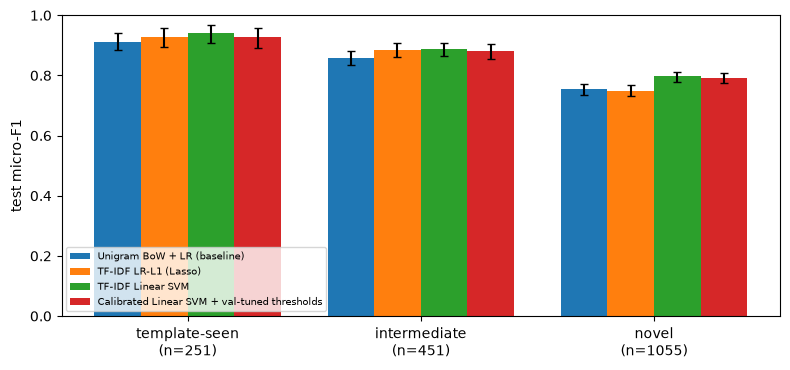

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bk = ["template-seen", "intermediate", "novel"]; w = 0.2
for i, name in enumerate(overlap_te.model.unique()):
    g = overlap_te[overlap_te.model == name].set_index("bucket").loc[bk]
    ax.bar(np.arange(3) + i * w, g.micro_f1, w, yerr=[g.micro_f1 - g.ci_lo, g.ci_hi - g.micro_f1],
           capsize=3, label=name)
ax.set_xticks(np.arange(3) + 1.5 * w)
ax.set_xticklabels([f"{b}\n(n={int((te_df.bucket == b).sum())})" for b in bk])
ax.set_ylabel("test micro-F1"); ax.set_ylim(0, 1); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(FIGURES / "test_overlap_buckets.png", dpi=150); plt.show()

## 10.4 Shortcut stress tests on test

In [7]:
vocab = vec.get_feature_names_out(); vidx = {t: i for i, t in enumerate(vocab)}
df_counts = np.asarray((A > 0).sum(axis=0)).ravel()
srows = []
for name in ["TF-IDF Linear SVM", "TF-IDF LR-L1 (Lasso)"]:
    m = fitted[name]; W, b = sc.linear_coefs(m); pool = sc.neutral_topic_pool(W, vocab, df_counts)
    bp = m.predict(T); ii, kk = np.where((Y_te == 1) & (bp == 1)); txt = [X_te.iloc[i] for i in ii]
    for test, (new, nsw) in {"topic swap (top-weighted)": sc.topic_substitution(txt, kk, W, vidx, pool, 3, "top"),
                             "topic swap (random control)": sc.topic_substitution(txt, kk, W, vidx, pool, 3, "random"),
                             "cue synonym swap": sc.cue_synonym_swap(txt)}.items():
        P = m.predict(vec.transform(new)); flip = P[np.arange(len(kk)), kk] == 0; e = nsw > 0
        srows.append({"model": name, "test": test, "true positives": len(kk), "edited": int(e.sum()),
                      "flip rate": float(flip[e].mean())})
stress_te = pd.DataFrame(srows); stress_te.round(3)

,model,test,true positives,edited,flip rate
0,TF-IDF Linear SVM,topic swap (top-weighted),1952,1951,0.223
1,TF-IDF Linear SVM,topic swap (random control),1952,1952,0.055
2,TF-IDF Linear SVM,cue synonym swap,1952,1499,0.089
3,TF-IDF LR-L1 (Lasso),topic swap (top-weighted),1825,1773,0.222
4,TF-IDF LR-L1 (Lasso),topic swap (random control),1825,1825,0.066
5,TF-IDF LR-L1 (Lasso),cue synonym swap,1825,1390,0.108


In [8]:
mrows = []
for vname, keep in {"full text": ["topic", "cue", "function"], "no topic words": ["cue", "function"],
                    "no cue words": ["topic", "function"], "topic words only": ["topic"]}.items():
    Tm = vec.transform(sc.mask_texts(X_te, keep))
    for name in ["TF-IDF Linear SVM", "TF-IDF LR-L1 (Lasso)"]:
        mrows.append({"input": vname, "model": name, "macro_f1": scores(Y_te, fitted[name].predict(Tm))["macro_f1"]})
mask_te = pd.DataFrame(mrows); mask_te.pivot(index="input", columns="model", values="macro_f1").round(3)

model,TF-IDF LR-L1 (Lasso),TF-IDF Linear SVM
input,,
full text,0.773,0.805
no cue words,0.657,0.715
no topic words,0.634,0.670
topic words only,0.459,0.472


## 10.5 Binary detectors for the three focus fallacies (proposal)
One LinearSVC per fallacy, configuration from notebook 09. Accuracy is shown next to the
majority-class ("always absent") baseline, as the proposal asked, with imbalance-aware
metrics beside it. The dataset has no fallacy-free arguments, so "absent" means "a different
fallacy".

In [9]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, average_precision_score
fb = sel["focus_binary"]; brow = []
for lab in fb["fallacies"]:
    k = LABELS.index(lab)
    m = LinearSVC(C=fb["C"], class_weight=cw(fb["class_weight"]), max_iter=20000).fit(A, Y_tr[:, k])
    p, sc_ = m.predict(T), m.decision_function(T)
    brow.append({"fallacy": lab, "test prevalence": Y_te[:, k].mean(), "majority-class accuracy": 1 - Y_te[:, k].mean(),
                 "SVM accuracy": accuracy_score(Y_te[:, k], p), "balanced accuracy": balanced_accuracy_score(Y_te[:, k], p),
                 "F1": f1_score(Y_te[:, k], p), "average precision": average_precision_score(Y_te[:, k], sc_)})
focus_te = pd.DataFrame(brow); focus_te.round(3)

,fallacy,test prevalence,majority-class accuracy,SVM accuracy,balanced accuracy,F1,average precision
0,Slippery Slope,0.276,0.724,0.946,0.941,0.906,0.961
1,Ad Hominem,0.068,0.932,0.969,0.905,0.783,0.867
2,False Dilemma,0.083,0.917,0.974,0.908,0.840,0.897


## 10.6 Error analysis
Which fallacies get confused with which? For every test argument we pair each **missed**
true label with each **spurious** predicted label.

In [10]:
yp = preds[best_name]
conf = pd.DataFrame(0, index=LABELS, columns=LABELS)
for i in range(len(Y_te)):
    fn = np.where((Y_te[i] == 1) & (yp[i] == 0))[0]; fp = np.where((Y_te[i] == 0) & (yp[i] == 1))[0]
    for a in fn:
        for b in fp: conf.iloc[a, b] += 1
pairs = conf.stack().sort_values(ascending=False).head(10).reset_index()
pairs.columns = ["true (missed)", "predicted instead", "count"]; pairs

,true (missed),predicted instead,count
0,Composition,Bandwagon / Popularity,15
1,Appeal to Authority,Bandwagon / Popularity,11
2,False Cause / Causality,Hasty Generalization,10
3,Bandwagon / Popularity,Hasty Generalization,8
4,Hasty Generalization,Bandwagon / Popularity,7
5,Composition,Hasty Generalization,6
6,Appeal to Authority,Hasty Generalization,6
7,Slippery Slope,Bandwagon / Popularity,6
8,False Cause / Causality,Slippery Slope,6
9,Straw Man,Ad Hominem,6


In [11]:
err = te_df[["id", "argument", "fallacies", "max_sim", "bucket"]].copy()
err["predicted"] = ["; ".join(np.array(LABELS)[r == 1]) or "(none)" for r in yp]
err["n_fn"] = ((Y_te == 1) & (yp == 0)).sum(1); err["n_fp"] = ((Y_te == 0) & (yp == 1)).sum(1)
err["status"] = np.where((err.n_fn == 0) & (err.n_fp == 0), "correct",
                np.where(err.n_fp == 0, "missed label(s)", np.where(err.n_fn == 0, "extra label(s)", "swapped")))
print(err.status.value_counts())
print("\nerror rate by overlap bucket:")
print(err.groupby("bucket").status.apply(lambda s: (s != "correct").mean()).round(3))

status
correct            1197
missed label(s)     208
extra label(s)      190
swapped             162
Name: count, dtype: int64

error rate by overlap bucket:
bucket
intermediate     0.191
novel            0.429
template-seen    0.084
Name: status, dtype: float64


In [12]:
pd.set_option("display.max_colwidth", 300)
rep = err[err.status != "correct"].sample(frac=1, random_state=0).groupby("status").head(4).sort_values("status")
rep[["status", "argument", "fallacies", "predicted", "bucket"]]

,status,argument,fallacies,predicted,bucket
112,extra label(s),"If we don't ban all social media now, it will lead to widespread mental health crises, and since most experts agree it's harmful, we must act immediately despite the lack of concrete evidence",Slippery Slope; Appeal to Authority,Slippery Slope; Appeal to Authority; Bandwagon / Popularity,novel
1392,extra label(s),"You should definitely get this smartphone - everyone in our school has one, and you'll feel left out if you don't join the trend.",Appeal to Emotion,Bandwagon / Popularity; Appeal to Emotion,novel
166,extra label(s),"My wealthy friend says we should invest in this company because everyone is doing it, and if we don't, we'll soon lose all our money and become homeless",Slippery Slope; Bandwagon / Popularity,Slippery Slope; Appeal to Authority; Bandwagon / Popularity,novel
1696,extra label(s),"Most flowers bloom in spring because that's when they typically open, and their spring blooming confirms the seasonal pattern.",Circular Reasoning,False Cause / Causality; Circular Reasoning,novel
1385,missed label(s),"Permitting smartphones in classrooms will cause students to stop paying attention entirely, which will inevitably result in failing grades, increased dropout rates, and ultimately a collapse of the education system.",Slippery Slope; False Cause / Causality,Slippery Slope,novel
802,missed label(s),"My headphones use electricity, and since they're part of my electronic collection, my entire collection must use exactly the same amount of power.",Composition; Equivocation; Red Herring,Composition,novel
604,missed label(s),"Since all the stars in our solar system orbit the Sun, and Earth is in our solar system, then everything in the universe must orbit the Sun.",Composition,(none),novel
376,missed label(s),"Everyone's getting solar panels on their roofs now. If you don't install them immediately, you'll fall behind and eventually end up with no electricity at all when the grid fails next year",Slippery Slope; Bandwagon / Popularity,Slippery Slope,novel
1585,swapped,"The local bakery sells delicious croissants, so all bakeries in this country must have excellent pastries.",Hasty Generalization,Composition,novel
330,swapped,"Our CEO says we need to cut costs immediately, and since everyone in the industry is doing layoffs to survive, firing 20% of our staff is clearly the only logical choice to prevent total bankruptcy",Bandwagon / Popularity; False Dilemma,Appeal to Authority; Bandwagon / Popularity,novel


## 10.7 Save everything for the website

In [13]:
out = {"test_table": test_tab.to_dict("records"), "per_class": pc.reset_index(names="label").to_dict("records"),
       "overlap": overlap_te.to_dict("records"), "stress": stress_te.to_dict("records"),
       "masking": mask_te.to_dict("records"), "confusion_pairs": pairs.to_dict("records"),
       "error_status": err.status.value_counts().to_dict(),
       "bucket_counts": te_df.bucket.value_counts().to_dict(), "focus_binary": focus_te.to_dict("records")}
(RESULTS / "test_summary.json").write_text(json.dumps(out, indent=2, default=float))
err.to_csv(RESULTS / "test_predictions.csv", index=False)
print("saved")

saved
